# Detección temprana de anomalías en aerogeneradores con datos SCADA mediante modelos de comportamiento normal

**Pregunta:** ¿con cuánta anticipación puede un modelo entrenado únicamente con operación sana detectar una falla de componente en un aerogenerador?

Datos: Parque A de *CARE to Compare* (Zenodo v6, 22 datasets). Toda la lógica está en `src/pipeline.py`; este notebook la ejecuta de principio a fin y muestra los resultados.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))

import pandas as pd
from IPython.display import Image, display
import pipeline as p
import figures as f

pd.set_option('display.max_columns', 30, 'display.width', 200)

## 1. Carga y limpieza de los datos

Si el Parque A no está en `data/`, se descarga solo esa carpeta del zip de Zenodo (HTTP Range, verificación CRC32). Entrenamiento: `status_type_id == 0`, potencia > 0, sin potencia limitada (potencia real < 90 % de la posible) y sin faltantes.

In [2]:
if not p.FARM_DIR.exists():
    import download
    download.main(dest=ROOT / 'data')

events = p.load_events()
print(events['event_label'].value_counts())
p.variables_table()

event_label
anomaly    12
normal     10
Name: count, dtype: int64


,rol,columna,nombre,descripcion_original
0,entrada,power_30_avg,Potencia activa (normalizada),Grid power
1,entrada,wind_speed_3_avg,Velocidad de viento (m/s),Windspeed
2,entrada,sensor_0_avg,Temperatura ambiente (°C),Ambient temperature
3,entrada,sensor_52_avg,Velocidad del rotor (rpm),Rotor rpm
4,objetivo,sensor_11_avg,Rodamiento caja multiplicadora,Temperature in gearbox bearing on high speed s...
5,objetivo,sensor_12_avg,Aceite caja multiplicadora,Temperature oil in gearbox
6,objetivo,sensor_13_avg,Rodamiento generador (lado acople),Temperature in generator bearing 2 (Drive End)
7,objetivo,sensor_14_avg,Rodamiento generador (lado opuesto),Temperature in generator bearing 1 (Non-Drive ...
8,objetivo,sensor_15_avg,Devanado estator fase 1,Temperature inside generator in stator winding...
9,objetivo,sensor_38_avg,Transformador fase L1,Temperature in HV transformer phase L1


In [3]:
p.summary_table(events)

,event_id,turbina,tipo,descripcion,filas_entrenamiento,filas_entrenamiento_limpias,filas_prediccion,inicio_evento,fin_evento,pct_conservado
0,0,0,anomaly,Generator bearing failure,52148,30959,2838,2023-08-06 06:10:00,2023-08-20 06:10:00,59.4
1,3,10,normal,,52185,27018,3302,2023-04-27 03:00:00,2023-05-18 01:10:00,51.8
2,10,10,anomaly,Gearbox failure,52323,30158,1269,2023-10-11 08:40:00,2023-10-18 08:40:00,57.6
3,13,21,normal,,50427,26646,3583,2023-05-03 13:20:00,2023-05-24 10:20:00,52.8
4,14,13,normal,,52296,33766,1901,2023-03-05 14:00:00,2023-03-12 18:40:00,64.6
5,17,10,normal,,52309,30110,2781,2023-11-02 15:20:00,2023-11-16 00:40:00,57.6
6,22,21,anomaly,Hydraulic group,51888,28017,1148,2023-08-12 09:50:00,2023-08-19 10:00:00,54.0
7,24,0,normal,,52289,30516,2714,2023-04-27 15:00:00,2023-05-11 11:20:00,58.4
8,25,11,normal,,52289,32238,2423,2023-05-23 06:50:00,2023-06-05 02:30:00,61.7
9,26,0,anomaly,Hydraulic group,52261,30302,1441,2023-10-12 10:20:00,2023-10-19 10:20:00,58.0


## 2 a 4. Modelo de comportamiento normal, detección y evaluación

Por dataset: un modelo por temperatura de componente (regresión lineal y gradient boosting), validación temporal con el último 20 % del entrenamiento, residuo estandarizado, EWMA (alfa = 0,05), umbral = cuantil 0,995 del puntaje en validación y contador de criticidad oficial (72). CARE se calcula con el código oficial de los autores (`src/efd_care`). El análisis de sensibilidad varía el cuantil del umbral.

In [4]:
events, results, metrics, table, scored = p.run_all()
metrics.groupby(['objetivo', 'modelo'])['rmse_val'].median().unstack().round(2)

  File "C:\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Python312\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


modelo,gbm,lineal
objetivo,,
sensor_11_avg,0.97,1.85
sensor_12_avg,1.47,2.90
sensor_13_avg,4.75,4.85
sensor_14_avg,4.50,4.42
sensor_15_avg,2.93,4.05
sensor_38_avg,6.08,6.23
sensor_41_avg,2.24,3.79


In [5]:
w = metrics.pivot_table(index=['event_id', 'objetivo'], columns='modelo', values='rmse_val')
print(f"GBM con menor RMSE en {(w['gbm'] < w['lineal']).sum()} de {len(w)} combinaciones dataset-componente")

GBM con menor RMSE en 127 de 154 combinaciones dataset-componente


### Resultados con el umbral principal (cuantil 0,995)

In [6]:
results[['event_id', 'modelo', 'tipo', 'descripcion', 'detectado', 'max_criticidad', 'anticipacion_dias', 'pct_puntos_alarma']].round(2)

,event_id,modelo,tipo,descripcion,detectado,max_criticidad,anticipacion_dias,pct_puntos_alarma
88,0,lineal,anomaly,Generator bearing failure,False,6,NaN,0.60
89,3,lineal,normal,,False,9,NaN,0.94
90,10,lineal,anomaly,Gearbox failure,False,0,NaN,0.00
91,13,lineal,normal,,False,35,NaN,1.31
92,14,lineal,normal,,False,3,NaN,0.47
93,17,lineal,normal,,False,3,NaN,0.79
94,22,lineal,anomaly,Hydraulic group,False,3,NaN,0.52
95,24,lineal,normal,,False,7,NaN,0.48
96,25,lineal,normal,,False,7,NaN,1.65
97,26,lineal,anomaly,Hydraulic group,False,0,NaN,0.56


In [7]:
table[table['q'] == p.THRESHOLD_Q].round(3)

,modelo,q,CARE,coverage,accuracy,reliability,earliness,anomalias_detectadas,anomalias_total,falsas_alarmas,normales_total,anticipacion_mediana_dias,anticipacion_min_dias,anticipacion_max_dias
4,lineal,0.995,0.0,0.038,0.992,0.0,0.009,0,12,0,10,NaN,NaN,NaN
10,gbm,0.995,0.0,0.027,0.989,0.0,0.004,0,12,0,10,NaN,NaN,NaN


### Análisis de sensibilidad del umbral

In [8]:
table.round(3)

,modelo,q,CARE,coverage,accuracy,reliability,earliness,anomalias_detectadas,anomalias_total,falsas_alarmas,normales_total,anticipacion_mediana_dias,anticipacion_min_dias,anticipacion_max_dias
0,lineal,0.900,0.547,0.275,0.908,0.536,0.108,3,12,1,10,9.285,5.715,29.792
1,lineal,0.950,0.476,0.171,0.950,0.250,0.057,1,12,1,10,29.722,29.722,29.722
2,lineal,0.980,0.475,0.088,0.976,0.312,0.024,1,12,0,10,23.069,23.069,23.069
3,lineal,0.990,0.000,0.058,0.986,0.000,0.014,0,12,0,10,NaN,NaN,NaN
4,lineal,0.995,0.000,0.038,0.992,0.000,0.009,0,12,0,10,NaN,NaN,NaN
5,lineal,0.999,0.000,0.010,0.997,0.000,0.002,0,12,0,10,NaN,NaN,NaN
6,gbm,0.900,0.503,0.271,0.900,0.357,0.090,2,12,2,10,15.767,1.750,29.785
7,gbm,0.950,0.508,0.179,0.948,0.417,0.047,2,12,1,10,15.722,1.715,29.729
8,gbm,0.980,0.498,0.104,0.974,0.417,0.021,2,12,1,10,15.330,1.660,29.000
9,gbm,0.990,0.404,0.046,0.984,0.000,0.008,0,12,1,10,NaN,NaN,NaN


In [9]:
sens = pd.read_csv(p.OUT_DIR / 'resultados_sensibilidad.csv')
sens[sens['detectado']][['modelo', 'q', 'event_id', 'tipo', 'descripcion', 'primera_deteccion', 'anticipacion_dias', 'componente_alarma']].round(2)

,modelo,q,event_id,tipo,descripcion,primera_deteccion,anticipacion_dias,componente_alarma
3,lineal,0.90,13,normal,NaN,NaN,NaN,NaN
11,lineal,0.90,40,anomaly,Generator bearing failure,2022-12-27 18:00:00,29.79,Aceite grupo hidráulico
13,lineal,0.90,45,anomaly,Hydraulic group,2023-04-21 01:00:00,5.72,Rodamiento caja multiplicadora
19,lineal,0.90,73,anomaly,Hydraulic group,2023-06-08 04:50:00,9.28,Rodamiento generador (lado opuesto)
25,lineal,0.95,13,normal,NaN,NaN,NaN,NaN
33,lineal,0.95,40,anomaly,Generator bearing failure,2022-12-27 19:40:00,29.72,Aceite grupo hidráulico
55,lineal,0.98,40,anomaly,Generator bearing failure,2023-01-03 11:20:00,23.07,Aceite grupo hidráulico
132,gbm,0.90,0,anomaly,Generator bearing failure,2023-08-18 12:10:00,1.75,Rodamiento generador (lado acople)
135,gbm,0.90,13,normal,NaN,NaN,NaN,NaN
142,gbm,0.90,38,normal,NaN,NaN,NaN,NaN


## Figuras

RMSE ventana figura 2: {'gbm': 1.4513561426201258, 'lineal': 3.0787713294328163}


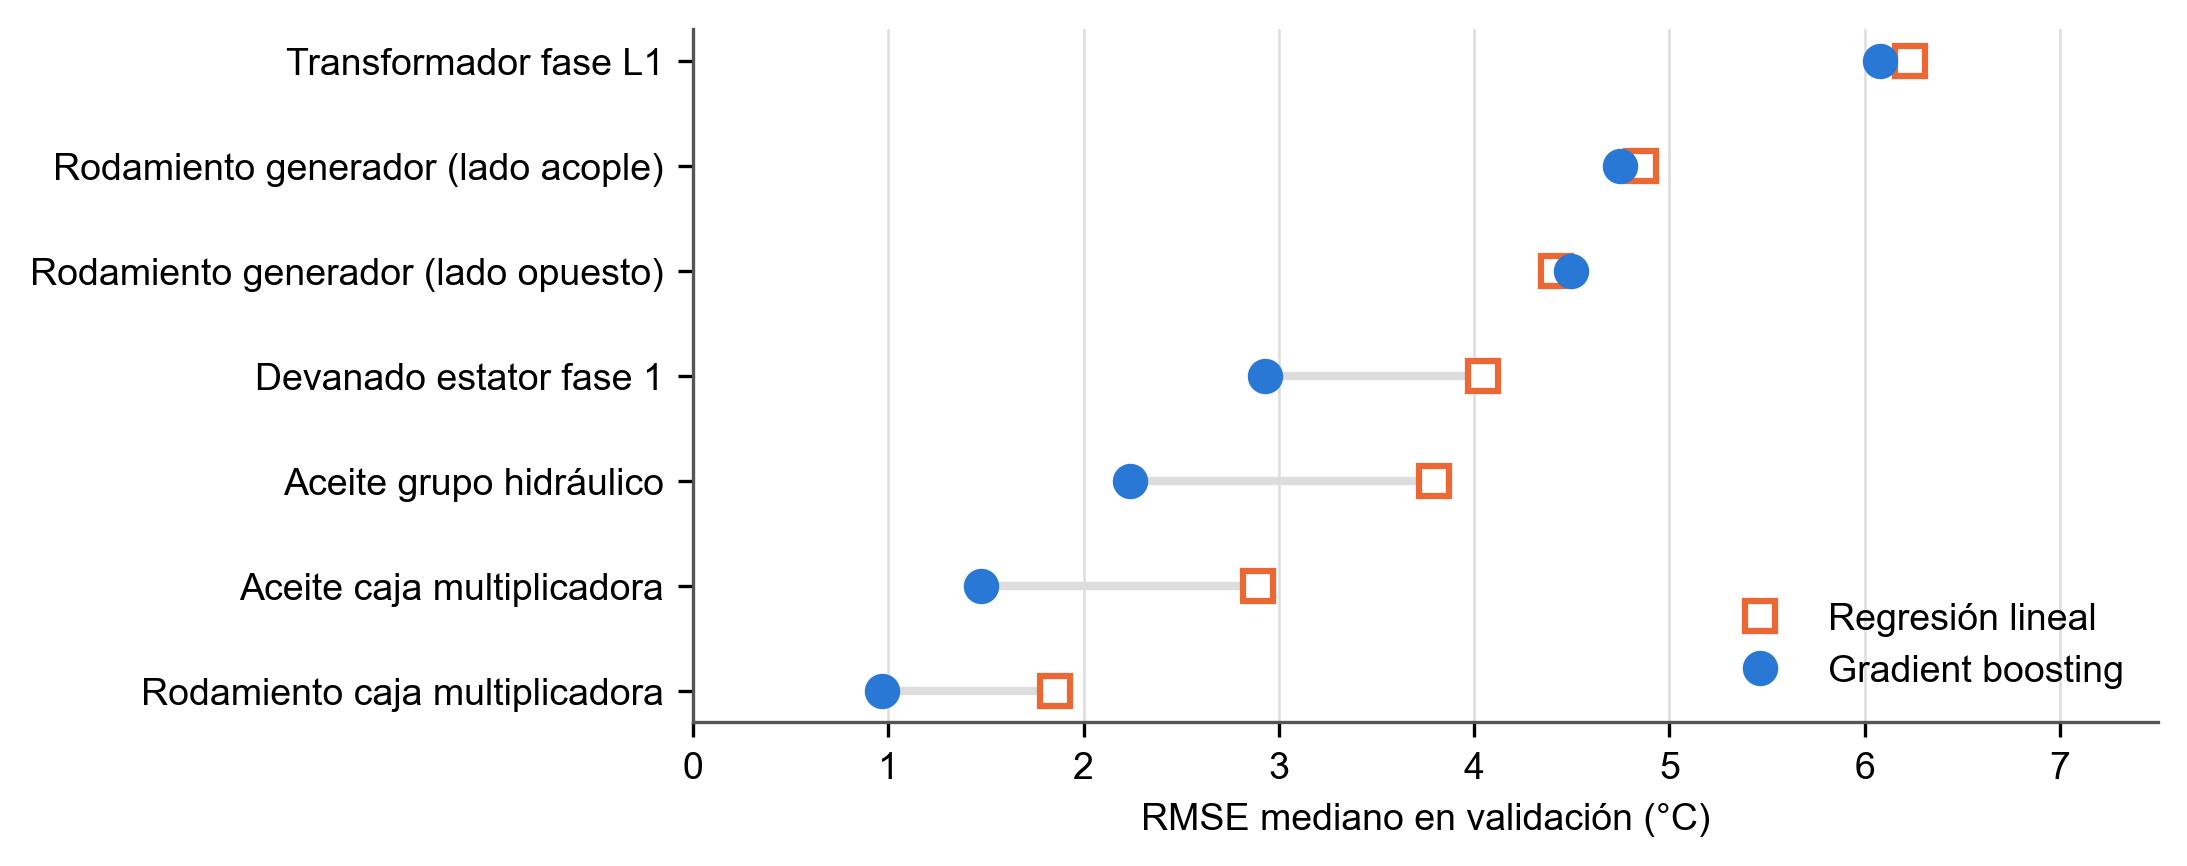

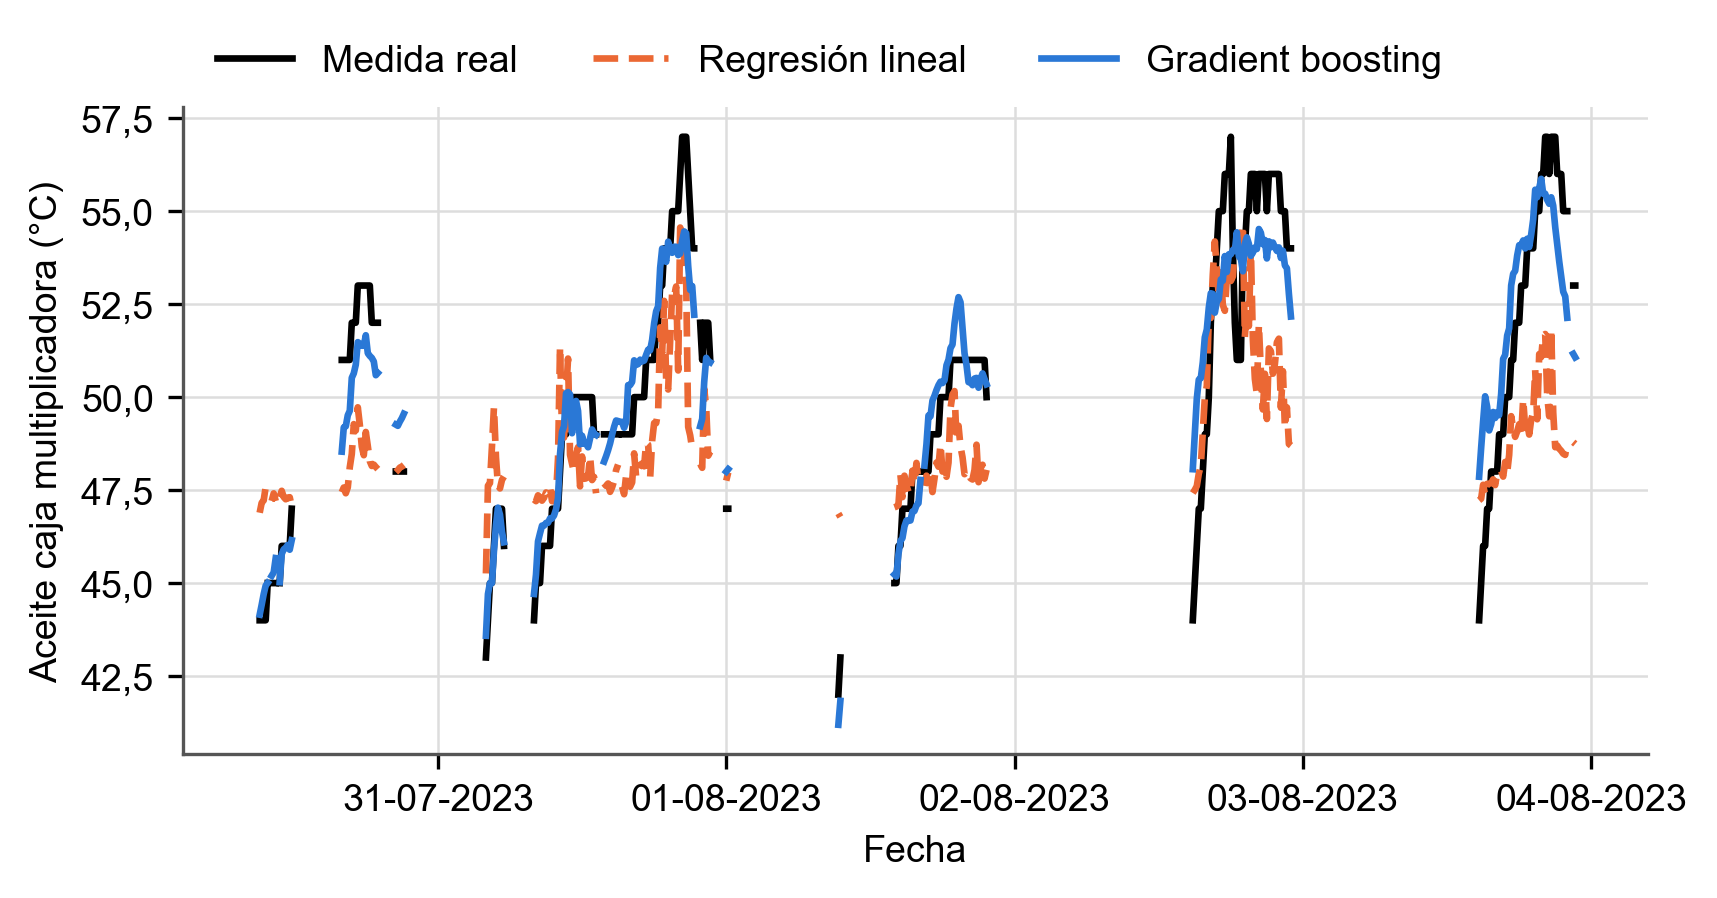

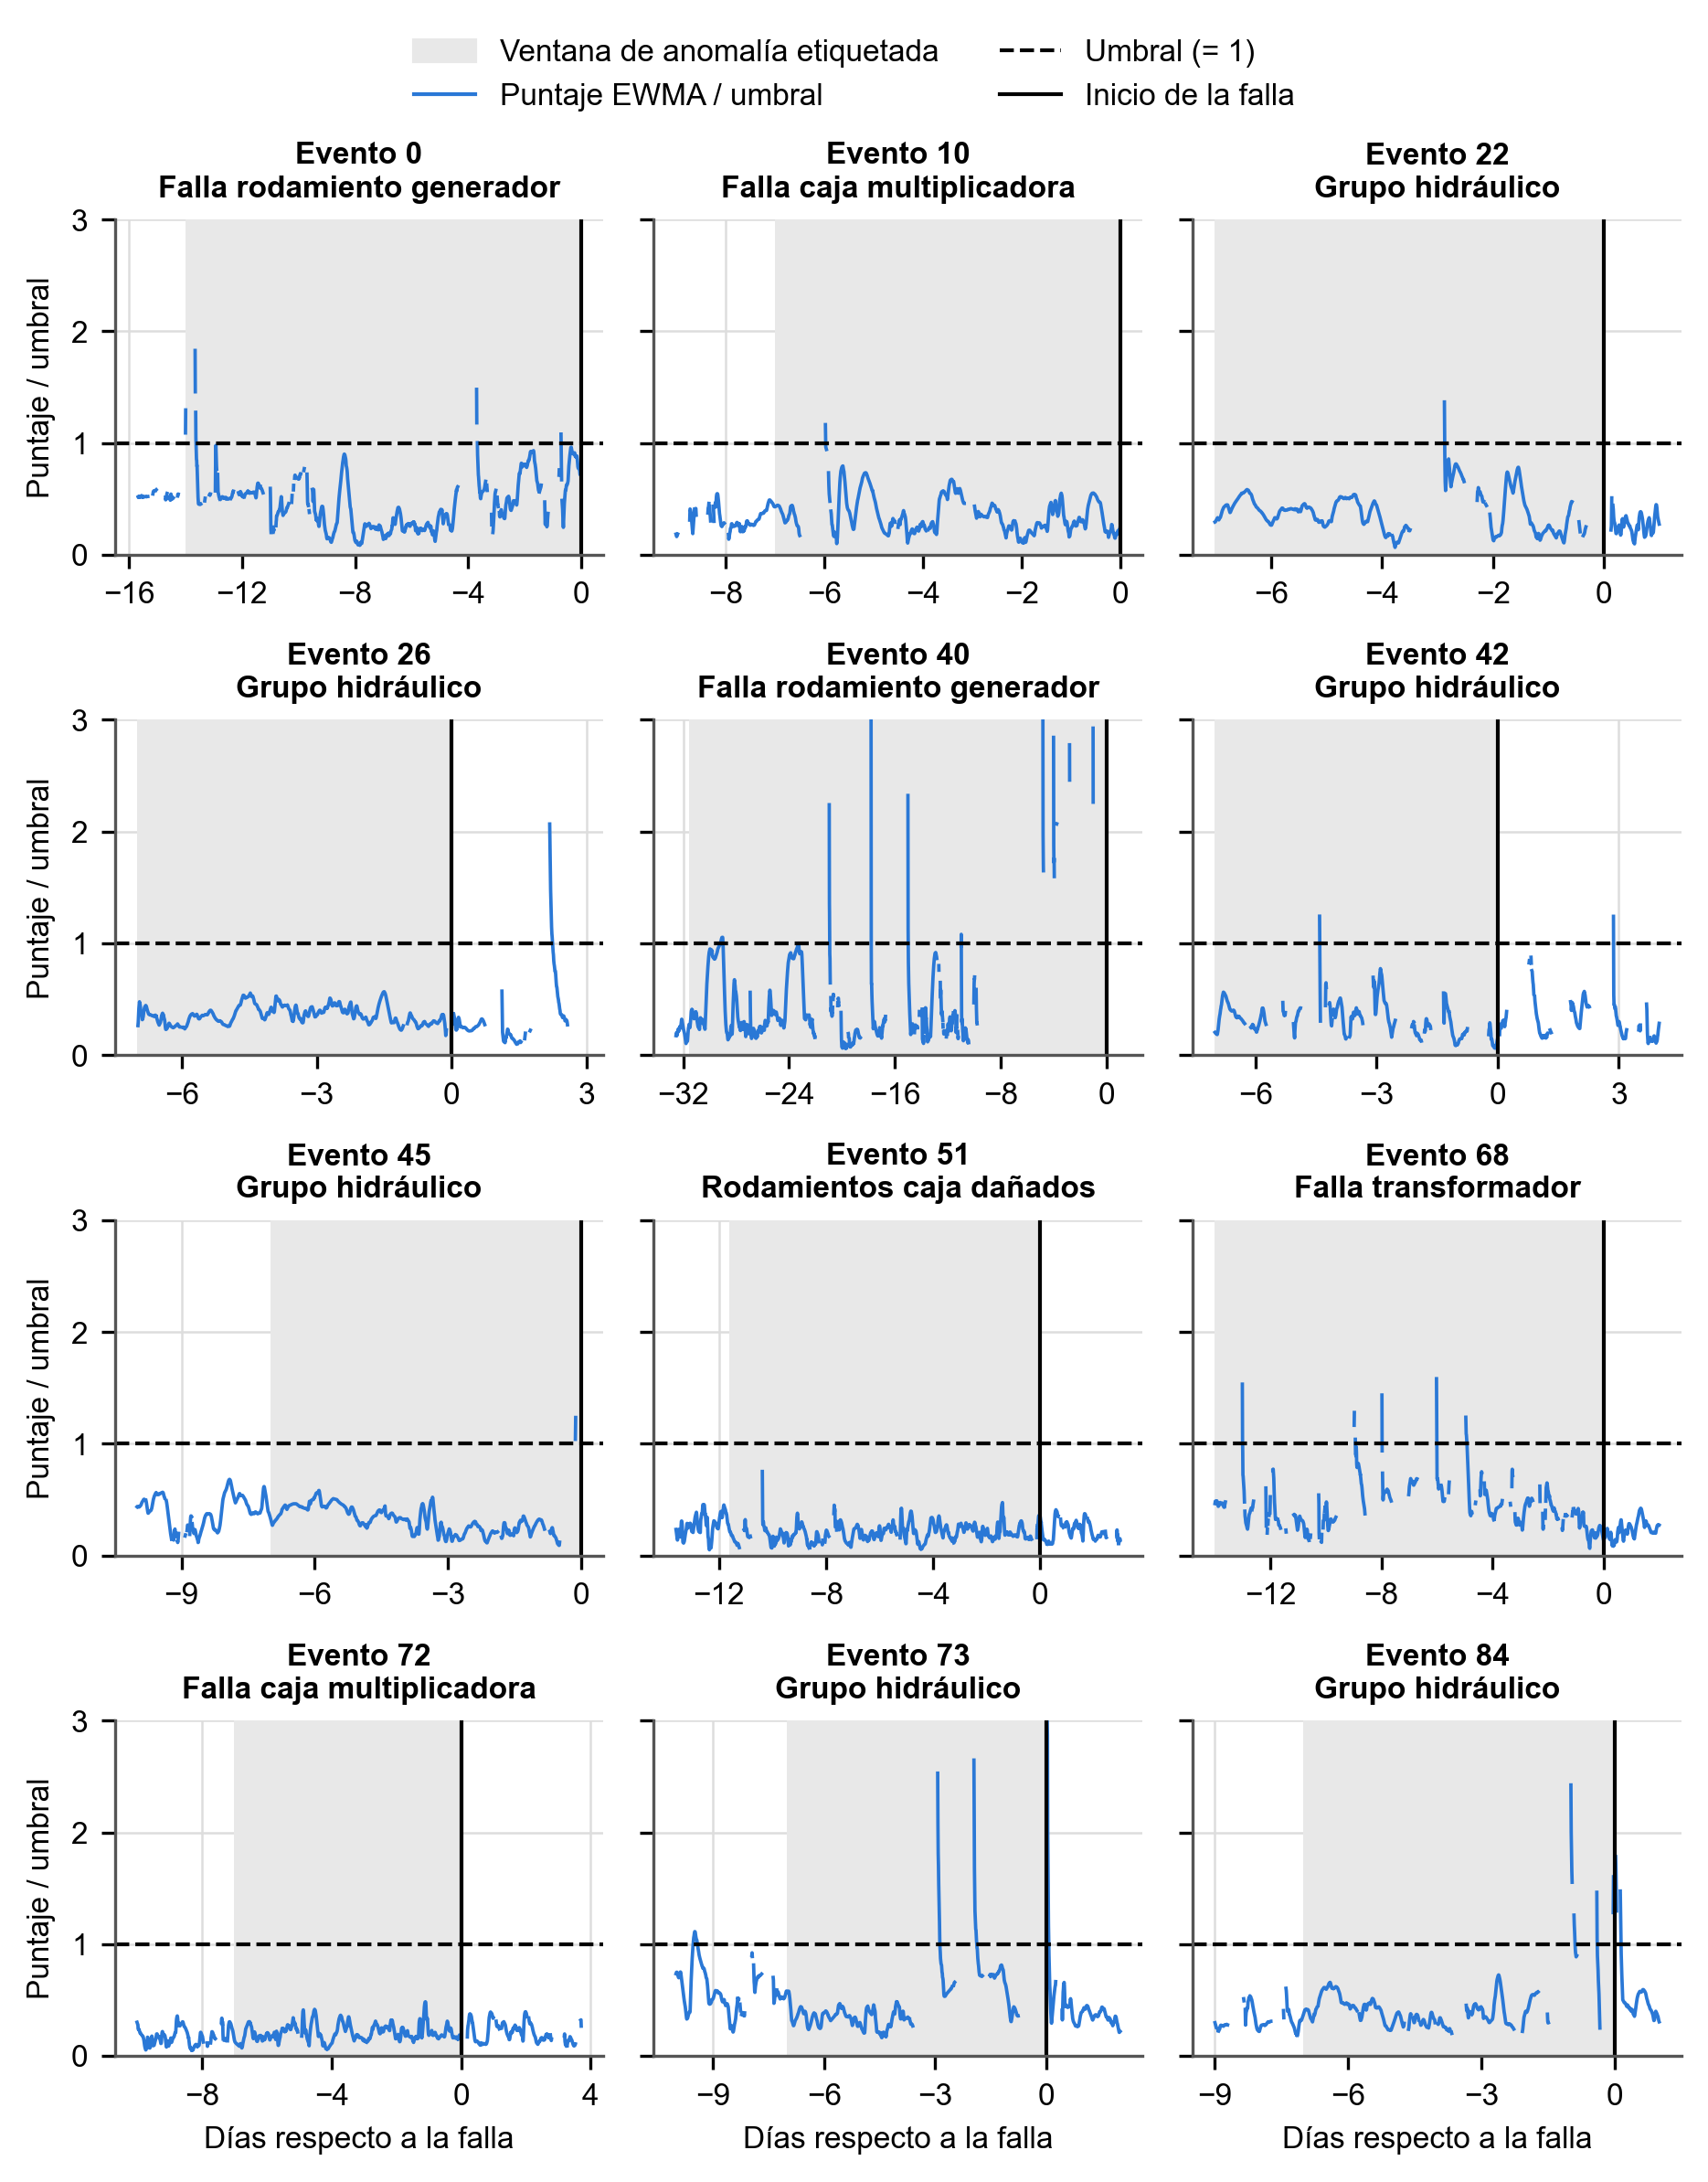

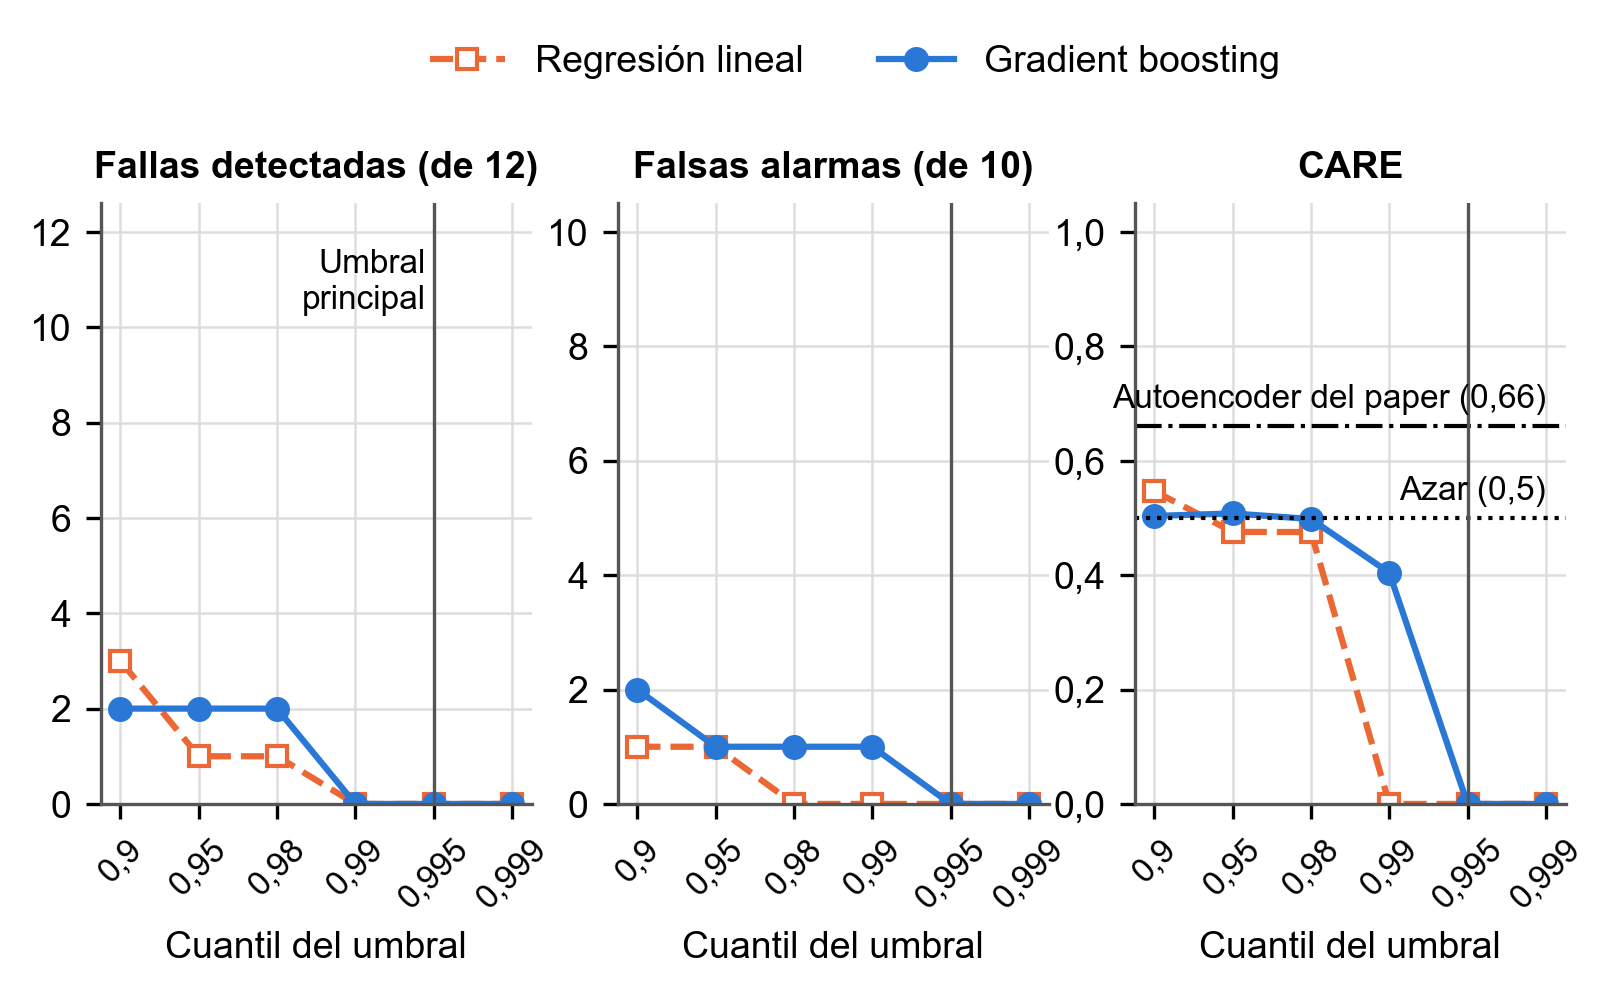

In [10]:
paths, err = f.make_all(events, results, metrics, table, scored)
print('RMSE ventana figura 2:', err)
for path in paths:
    display(Image(filename=str(path), width=800))

## Respuesta a la pregunta

In [11]:
main = table[table['q'] == p.THRESHOLD_Q].set_index('modelo')
for kind in ('lineal', 'gbm'):
    r = main.loc[kind]
    print(f"{kind}: {int(r.anomalias_detectadas)}/{int(r.anomalias_total)} fallas detectadas, "
          f"{int(r.falsas_alarmas)}/{int(r.normales_total)} falsas alarmas, CARE = {r.CARE:.2f}")
det = sens[sens['detectado'] & (sens['tipo'] == 'anomaly')]
print(f"Relajando el umbral (cuantil 0,90 a 0,98) se detectan como máximo "
      f"{int(table['anomalias_detectadas'].max())} de 12 fallas, con anticipaciones entre "
      f"{det['anticipacion_dias'].min():.1f} y {det['anticipacion_dias'].max():.1f} días.")

lineal: 0/12 fallas detectadas, 0/10 falsas alarmas, CARE = 0.00
gbm: 0/12 fallas detectadas, 0/10 falsas alarmas, CARE = 0.00
Relajando el umbral (cuantil 0,90 a 0,98) se detectan como máximo 3 de 12 fallas, con anticipaciones entre 1.7 y 29.8 días.
